## <span style="color:purple"> Graph Time Series Plots Variability with Depth </span>

### <span style="color:purple"> Plotting function </span>

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

position_colours = {"upper": "tab:blue", "middle": "tab:orange", "lower": "tab:green"}

def plot_time_series(df, am_id, ylim_temp=None, ylim_sal=None):
    # Sort through dataframe keys and extract the keys containing the specified borehole is (AMXX)
    df_bh = df[df["borehole"] == am_id]

    fig, (axT, axS) = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    # Iterate over this position ordering
    for position in position_order:
            cats_in_position = df_bh[df_bh["water_column_position"] == position]["cat"].unique()
            for cat in cats_in_position:
                dfp = df_bh[df_bh["cat"] == cat]
                
                colour = position_colours.get(position)

                axT.plot(dfp["time"], dfp["in_situ_temperature"], lw=0.8, label="_", color="gainsboro", zorder=1)
                axT.plot(dfp["time"], dfp["in_situ_temperature_smooth"], lw=0.8, label=f"{position}: cat{cat}", color=colour, zorder=2)
                axS.plot(dfp["time"], dfp["practical_salinity"],    lw=0.8, label="_", color="gainsboro", zorder=1)
                axS.plot(dfp["time"], dfp["practical_salinity_smooth"],    lw=0.8, label=f"{position}: cat{cat}", color=colour, zorder=2)

    axT.set_ylabel("In Situ Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    #axS.set_xlabel("Year")
    axT.set_title(f"{am_id} MicroCAT: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)

    axT.grid(True); axS.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Import and apply filtering to DataFrame </span>

<span style="color:purple"> When filtering using a large cutoff period it is often necessary to rely on interpolation
to fill gaps in the data which result from minor discontinuities in data collection. In the below script, we can define the length
of gaps which we are comfortable interpolating across. If we wish not to interpolate, we can set this variable to 0. </span>

In [22]:
from FilterFunctions import apply_lowpass_filter, lowpass_filter

df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the cutoff period for filtering in days 
cutoff_period_days = 30  # days
# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
interpolate_days = 7 # days
# Apply filtering to the DataFrame
# NOTE: cutoff_period is defined in terms of hours
df_filtered = apply_lowpass_filter(df, cutoff_period=cutoff_period_days*24, sampling_interval=0.5, max_gap_hours=interpolate_days*24)

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole location </span>

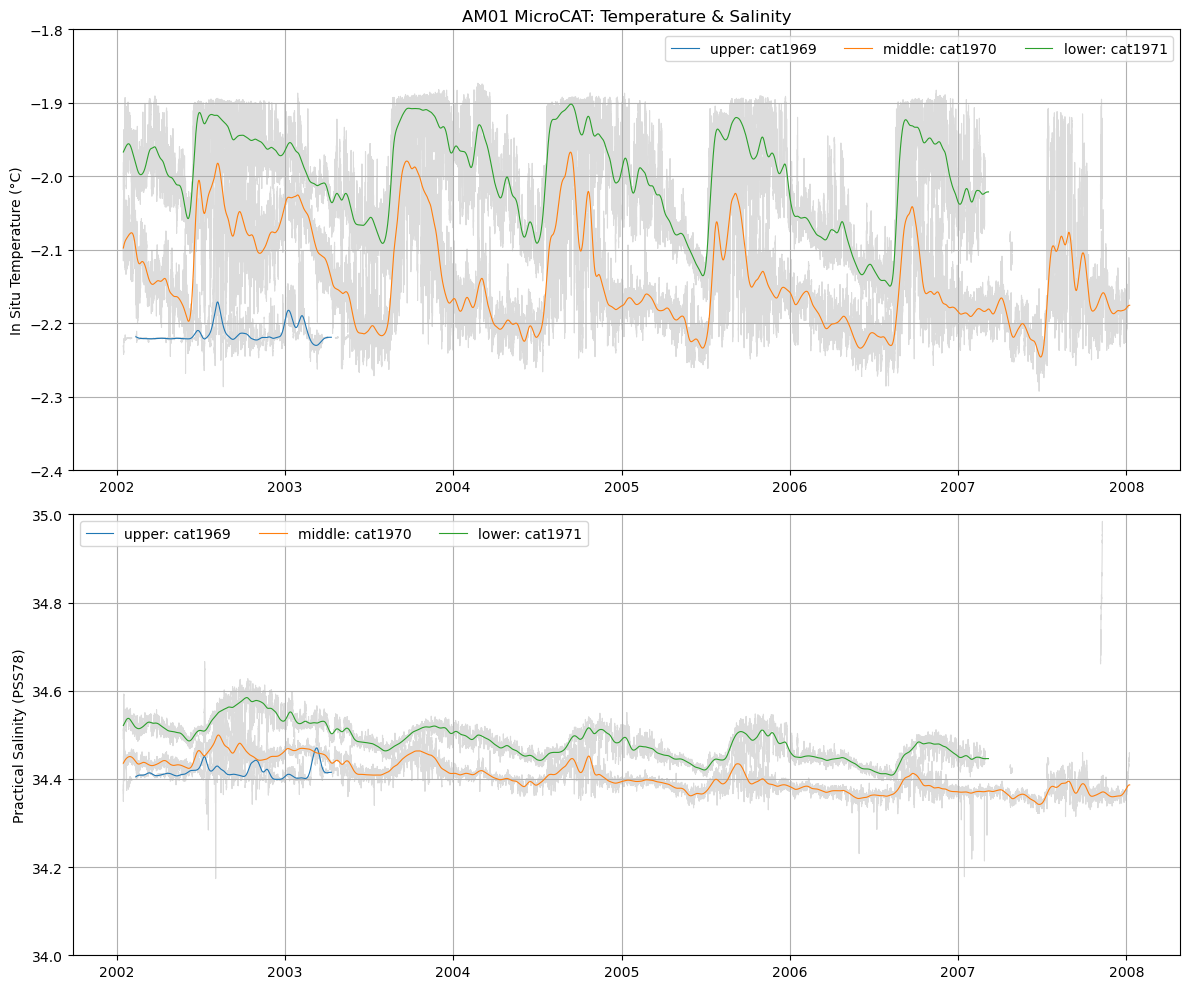

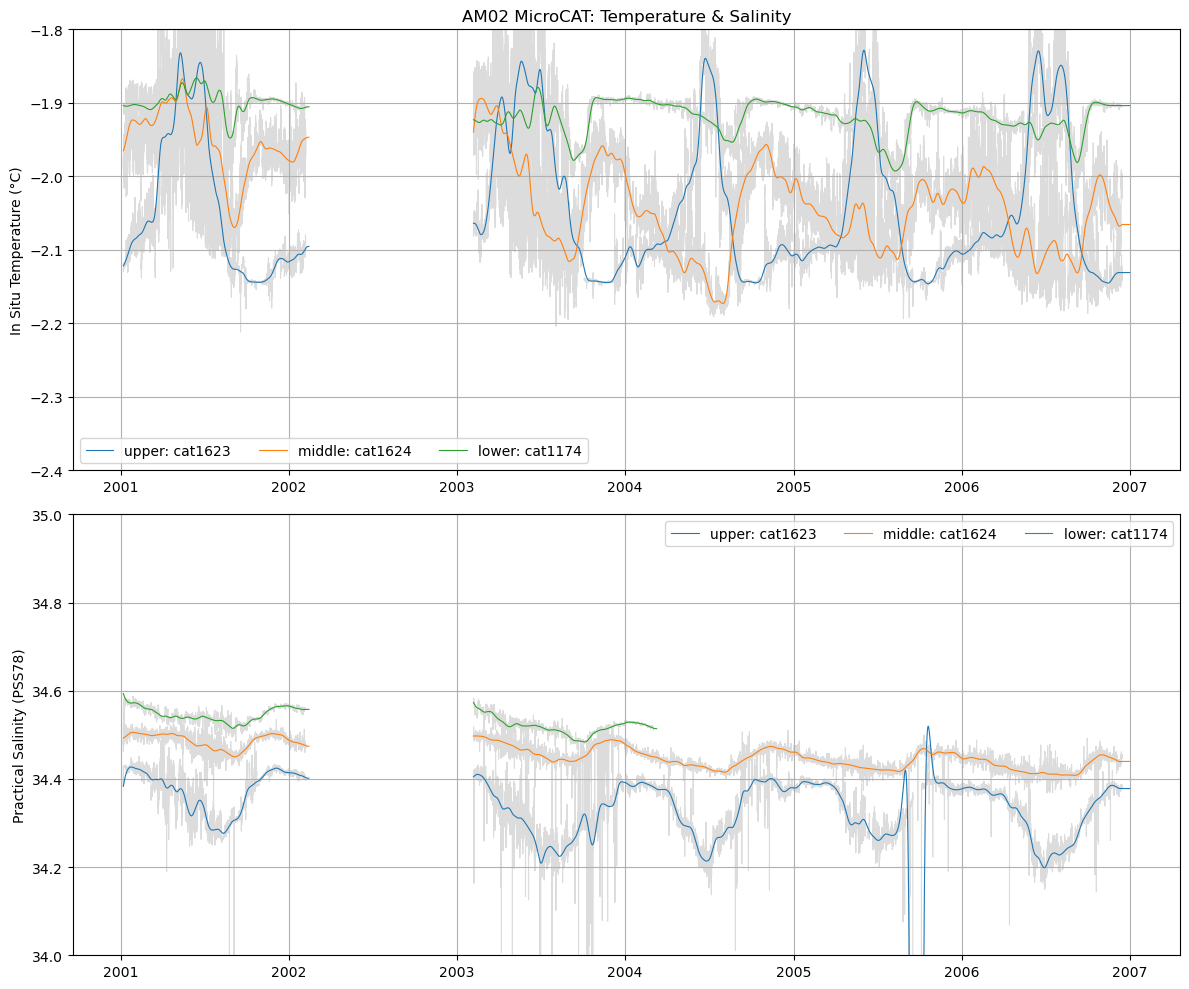

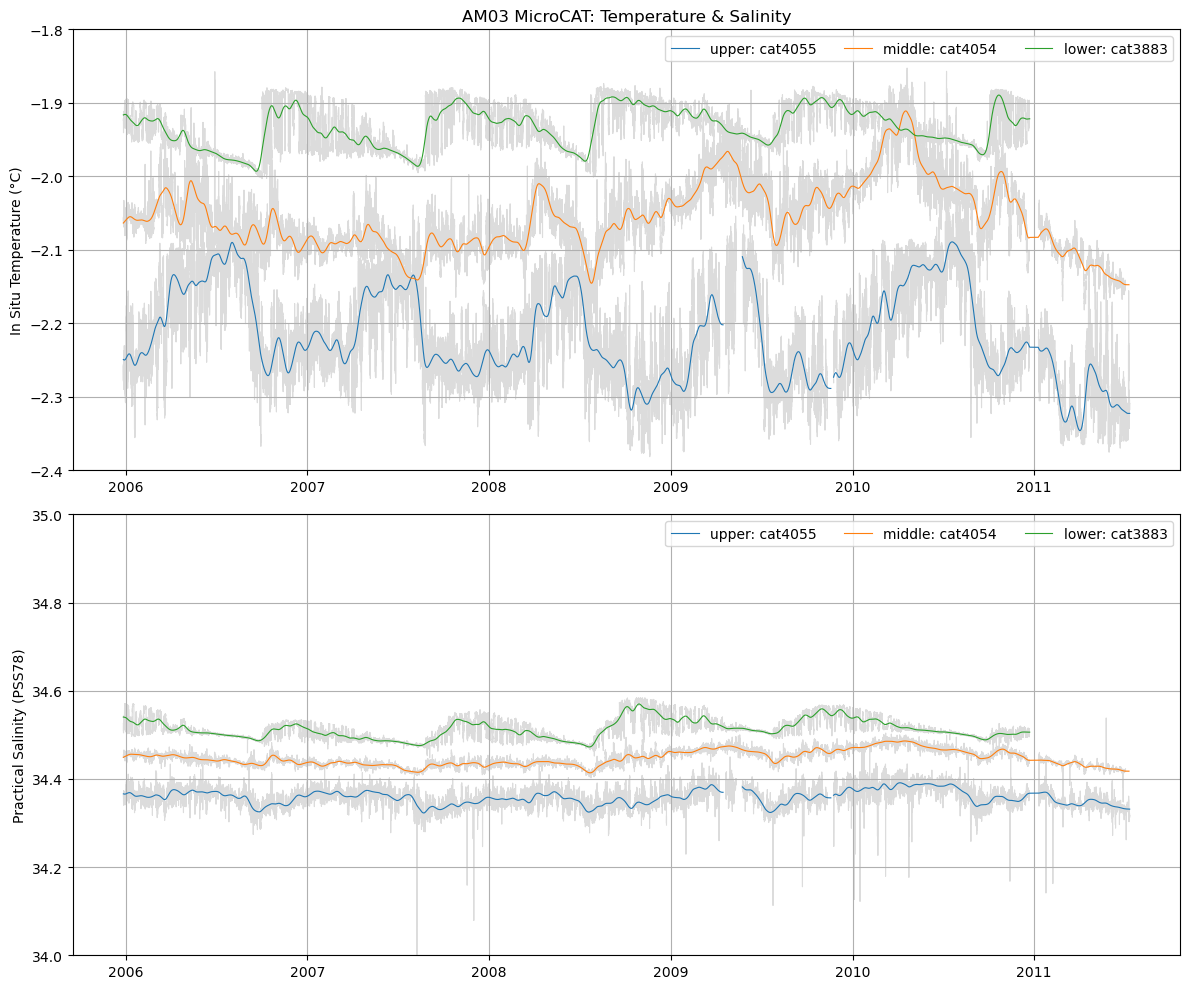

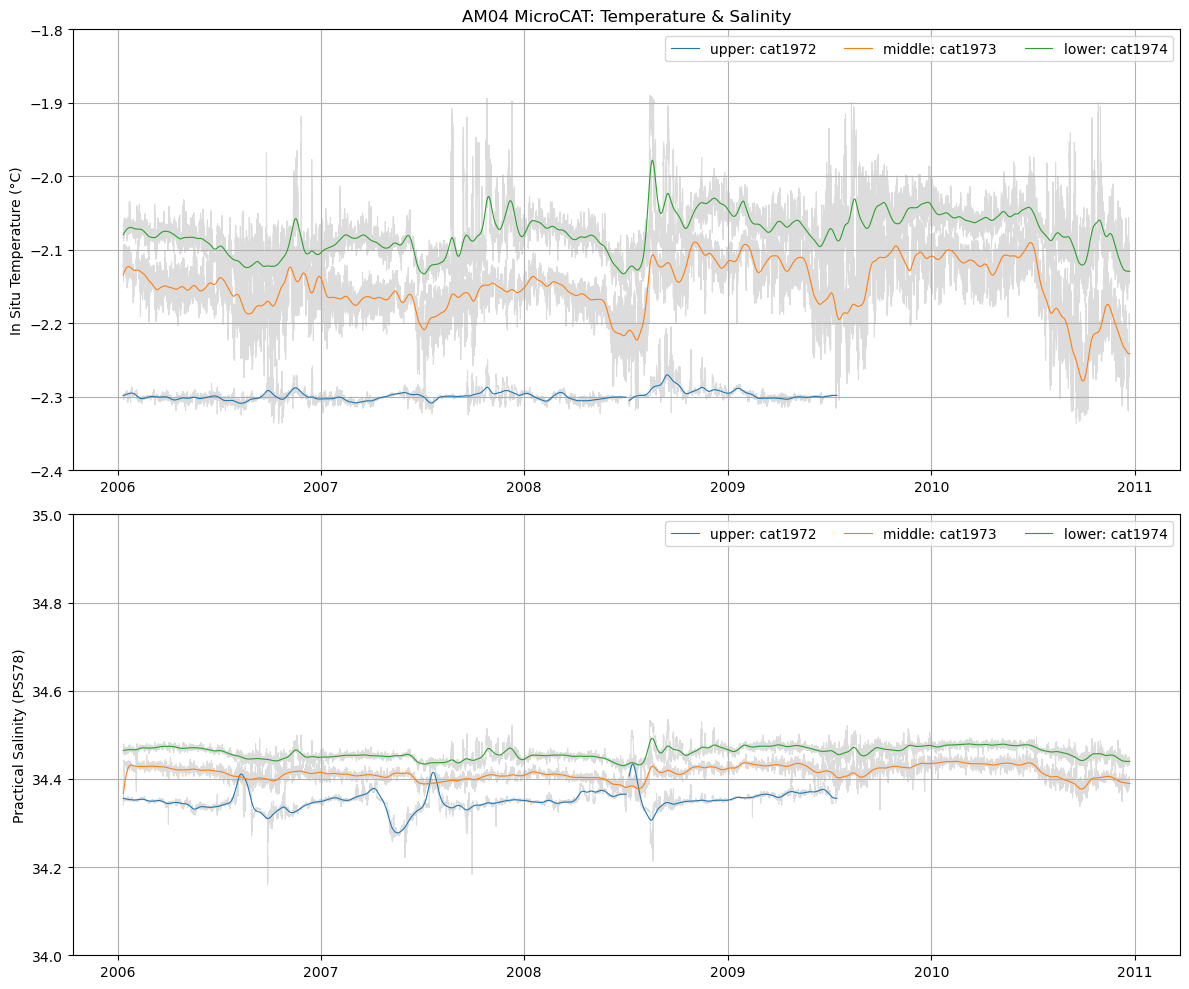

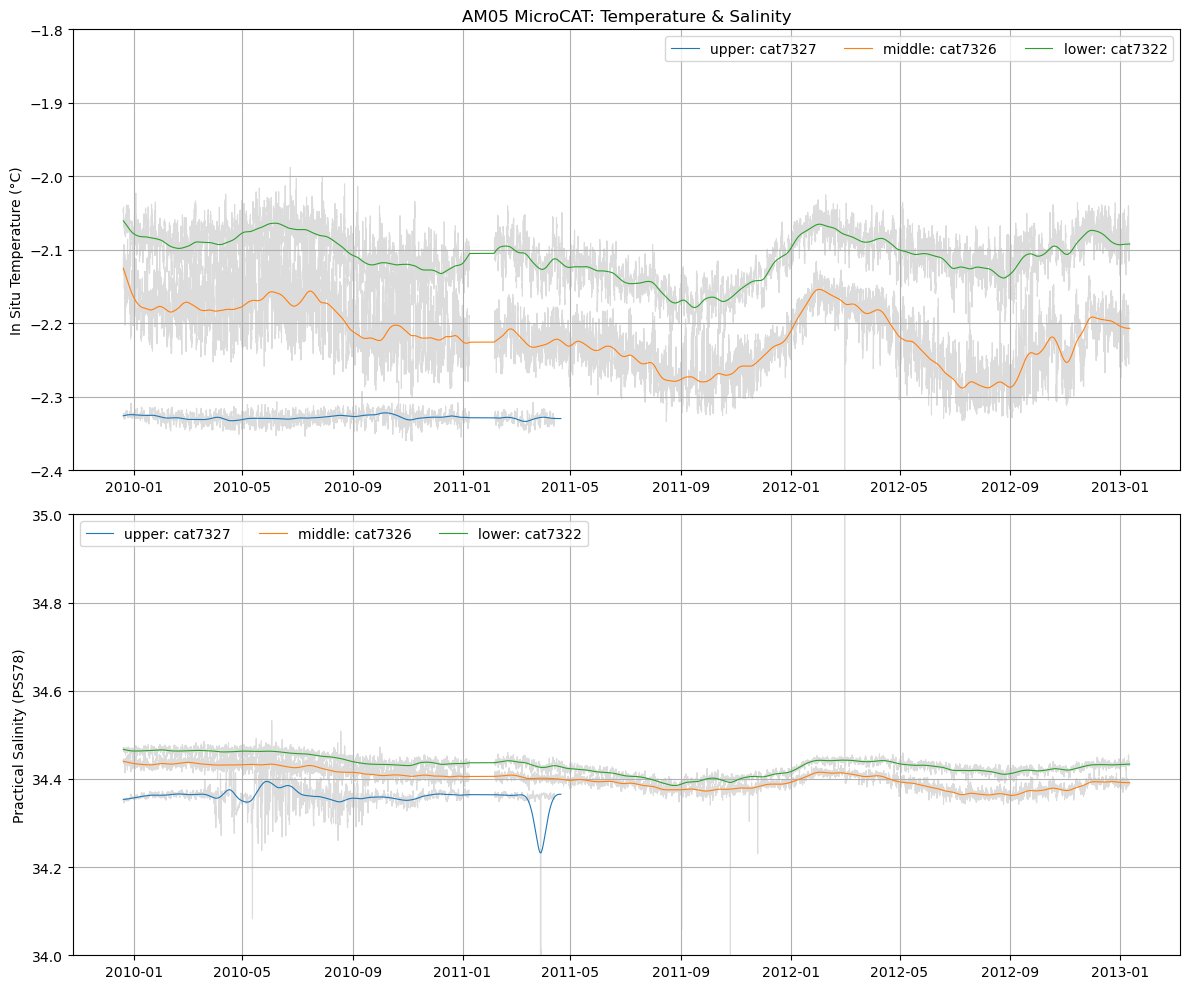

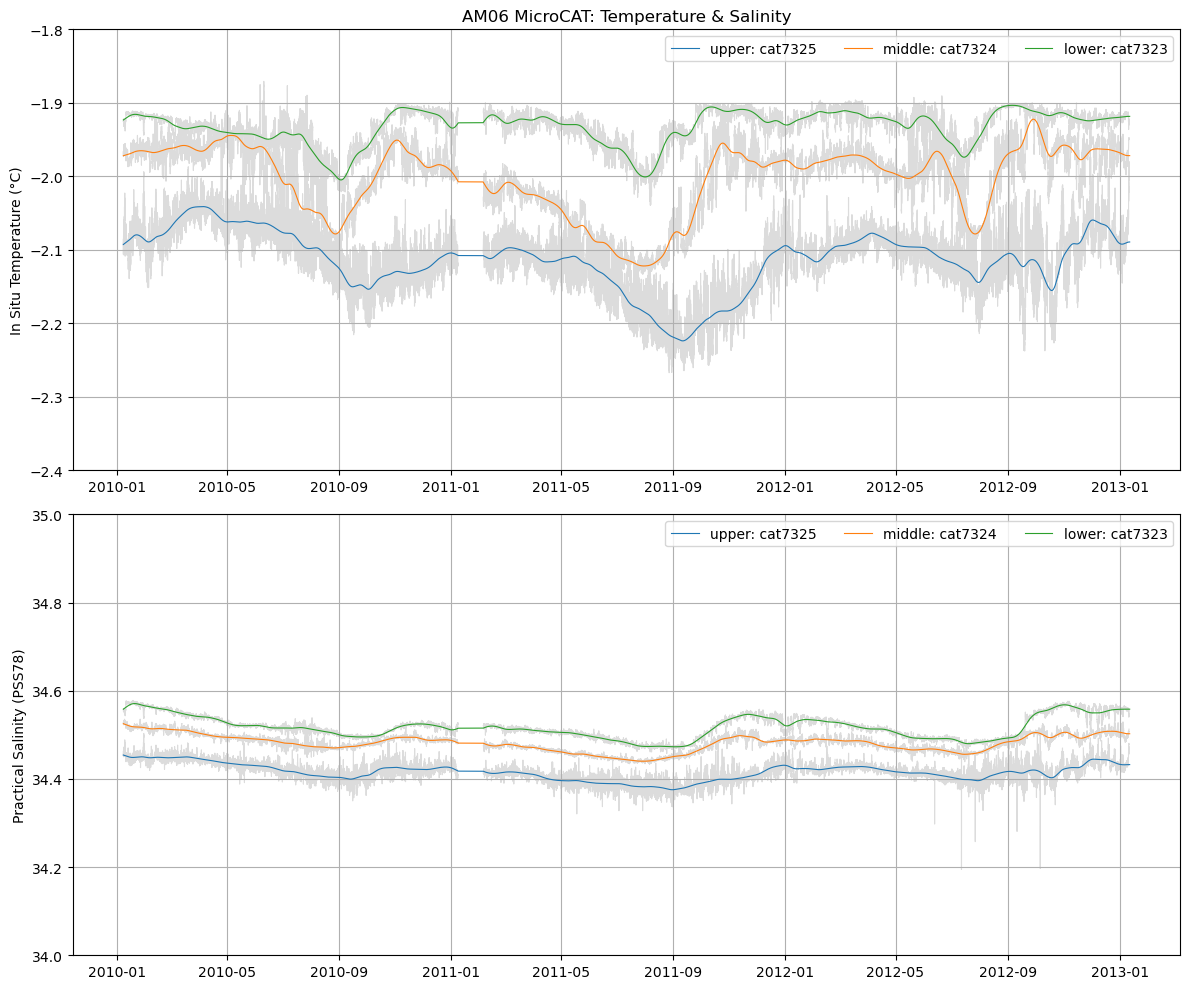

In [23]:
boreholes = sorted(df_filtered["borehole"].unique())
for am_id in boreholes:
    plot_time_series(df_filtered, am_id, (-2.4, -1.8), (34, 35))